# Household Energy (kWh) Prediction — Full ML Workflow

Workflow: EDA → Preprocessing → Train/Test Split → Model Training → Evaluation → Comparison → Best Model → Save

**Target:** `kwh` (daily electricity consumption).

**Problem type:** Regression. This workflow compares **Linear Regression**, **Random Forest Regressor**, **K-Nearest Neighbors Regressor (KNN)**, and **Support Vector Regression (SVR)**, then selects the best model based on validation RMSE.

**Note:** The final 14 days in the labeled training data are used as a chronological validation set. The competition `test.csv` is used only to generate the submission file.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Data

In [2]:
df = pd.read_csv("train.csv")
print("Dataset loaded successfully")
display(df.head())

Dataset loaded successfully


,row_id,household_id,date,num_residents,home_sqft,has_ev,has_solar,has_pool,heating_type,hvac_age_years,...,temp_max_c,humidity_pct,wind_kph,precip_mm,solar_index,is_weekend,is_holiday,prior_day_kwh,prior_week_avg_kwh,kwh
0,0,H00000,2025-01-02,4,1654,0,0,0,electric,25,...,-2.0,70,12.9,0.0,7.4,0,0,29.11,29.110000,32.91
1,1,H00000,2025-01-03,4,1654,0,0,0,electric,25,...,-3.9,37,10.1,0.0,6.3,0,0,32.91,31.010000,27.97
2,2,H00000,2025-01-04,4,1654,0,0,0,electric,25,...,-4.5,92,9.9,0.0,7.2,1,0,27.97,29.996667,30.81
3,3,H00000,2025-01-05,4,1654,0,0,0,electric,25,...,-3.1,65,15.1,0.0,3.3,1,0,30.81,30.200000,32.56
4,4,H00000,2025-01-06,4,1654,0,0,0,electric,25,...,-3.8,71,17.0,10.2,7.2,0,0,32.56,30.672000,31.93


## 3. Basic Inspection

In [3]:
print("Shape:", df.shape)
df.info()

Shape: (88500, 22)
<class 'pandas.DataFrame'>
RangeIndex: 88500 entries, 0 to 88499
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   row_id              88500 non-null  int64  
 1   household_id        88500 non-null  str    
 2   date                88500 non-null  str    
 3   num_residents       88500 non-null  int64  
 4   home_sqft           88500 non-null  int64  
 5   has_ev              88500 non-null  int64  
 6   has_solar           88500 non-null  int64  
 7   has_pool            88500 non-null  int64  
 8   heating_type        88500 non-null  str    
 9   hvac_age_years      88500 non-null  int64  
 10  temp_avg_c          88500 non-null  float64
 11  temp_min_c          88500 non-null  float64
 12  temp_max_c          88500 non-null  float64
 13  humidity_pct        88500 non-null  int64  
 14  wind_kph            88500 non-null  float64
 15  precip_mm           88500 non-null  float64
 

In [4]:
display(df.describe())

,row_id,num_residents,home_sqft,has_ev,has_solar,has_pool,hvac_age_years,temp_avg_c,temp_min_c,temp_max_c,humidity_pct,wind_kph,precip_mm,solar_index,is_weekend,is_holiday,prior_day_kwh,prior_week_avg_kwh,kwh
count,88500.00000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000,88500.000000
mean,54742.50000,3.489333,2622.456667,0.208667,0.178667,0.116000,13.184000,-0.402393,-3.904333,3.099979,59.975977,9.986673,1.417172,5.489279,0.288136,0.033898,26.109988,26.081123,26.064483
std,31610.10339,1.705458,1094.704175,0.406358,0.383075,0.320227,7.338943,4.950384,5.024928,5.026448,14.974369,6.310223,3.204005,2.144253,0.452897,0.180968,8.792819,7.655410,8.785717
min,0.00000,1.000000,709.000000,0.000000,0.000000,0.000000,1.000000,-18.700000,-23.500000,-15.700000,10.000000,0.100000,0.000000,0.000000,0.000000,0.000000,0.400000,2.362857,0.400000
25%,27371.25000,2.000000,1679.750000,0.000000,0.000000,0.000000,7.000000,-3.800000,-7.300000,-0.300000,50.000000,5.300000,0.000000,4.000000,0.000000,0.000000,20.300000,21.061607,20.260000
50%,54742.50000,3.500000,2707.500000,0.000000,0.000000,0.000000,13.000000,-0.600000,-4.000000,2.900000,60.000000,8.700000,0.000000,5.500000,0.000000,0.000000,25.310000,25.542857,25.260000
75%,82113.75000,5.000000,3513.250000,0.000000,0.000000,0.000000,20.000000,2.800000,-0.600000,6.400000,70.000000,13.300000,1.100000,7.000000,1.000000,0.000000,31.180000,30.732976,31.130000
max,109485.00000,6.000000,4498.000000,1.000000,1.000000,1.000000,25.000000,19.400000,16.300000,23.600000,99.000000,59.800000,46.600000,10.000000,1.000000,1.000000,76.200000,58.521429,76.200000


In [5]:
print("Households:", df["household_id"].nunique())
print("Date range:", df["date"].min(), "->", df["date"].max())
print("Days per household:", df.groupby("household_id").size().unique())

Households: 1500
Date range: 2025-01-02 -> 2025-03-01
Days per household: [59]


## 4. Missing Values and Duplicates

In [6]:
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

row_id                0
household_id          0
date                  0
num_residents         0
home_sqft             0
has_ev                0
has_solar             0
has_pool              0
heating_type          0
hvac_age_years        0
temp_avg_c            0
temp_min_c            0
temp_max_c            0
humidity_pct          0
wind_kph              0
precip_mm             0
solar_index           0
is_weekend            0
is_holiday            0
prior_day_kwh         0
prior_week_avg_kwh    0
kwh                   0
dtype: int64

Duplicate rows: 0


## 5. EDA

### 5.1 Target distribution

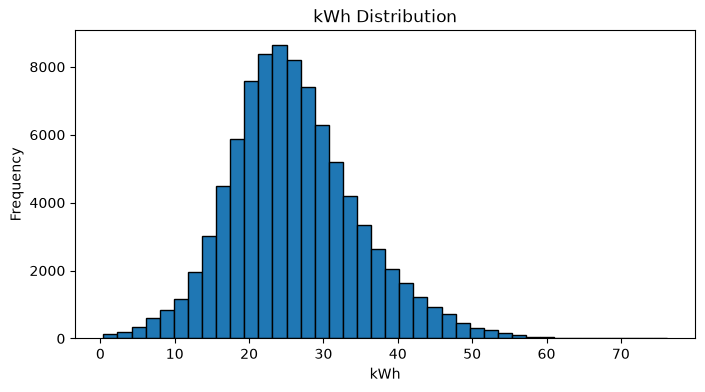

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(df["kwh"], bins=40, edgecolor="black")
plt.title("kWh Distribution")
plt.xlabel("kWh")
plt.ylabel("Frequency")
plt.show()

### 5.2 Average kWh by heating type

heating_type
electric     29.306308
gas          23.077618
heat_pump    26.204841
Name: kwh, dtype: float64

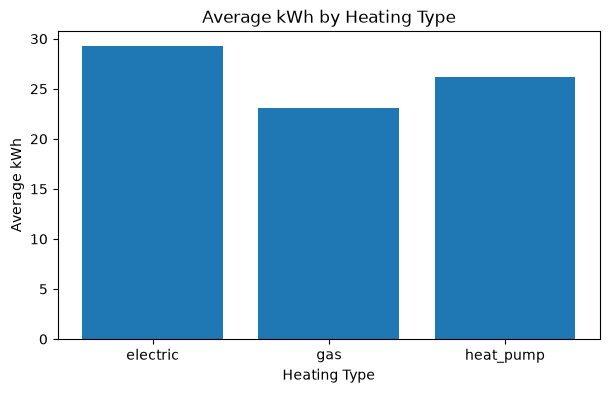

In [8]:
heating_mean = df.groupby("heating_type")["kwh"].mean()
display(heating_mean)

plt.figure(figsize=(7, 4))
plt.bar(heating_mean.index, heating_mean.values)
plt.title("Average kWh by Heating Type")
plt.xlabel("Heating Type")
plt.ylabel("Average kWh")
plt.show()

### 5.3 Average kWh for EV / Solar / Pool households

In [9]:
for col in ["has_ev", "has_solar", "has_pool"]:
    print(col)
    display(df.groupby(col)["kwh"].mean())

has_ev


has_ev
0    24.392698
1    32.404446
Name: kwh, dtype: float64

has_solar


has_solar
0    27.632058
1    18.858318
Name: kwh, dtype: float64

has_pool


has_pool
0    25.154813
1    32.996796
Name: kwh, dtype: float64

### 5.4 Temperature vs kWh

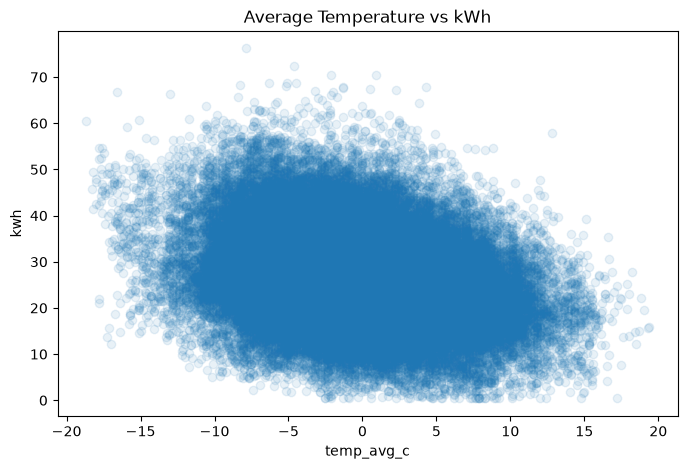

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temp_avg_c"], df["kwh"], alpha=0.1)
plt.title("Average Temperature vs kWh")
plt.xlabel("temp_avg_c")
plt.ylabel("kwh")
plt.show()

### 5.5 Weekend / holiday effect

In [11]:
display(df.groupby("is_weekend")["kwh"].mean())
display(df.groupby("is_holiday")["kwh"].mean())

is_weekend
0    25.664448
1    27.052805
Name: kwh, dtype: float64

is_holiday
0    26.020295
1    27.323857
Name: kwh, dtype: float64

### 5.6 Correlation

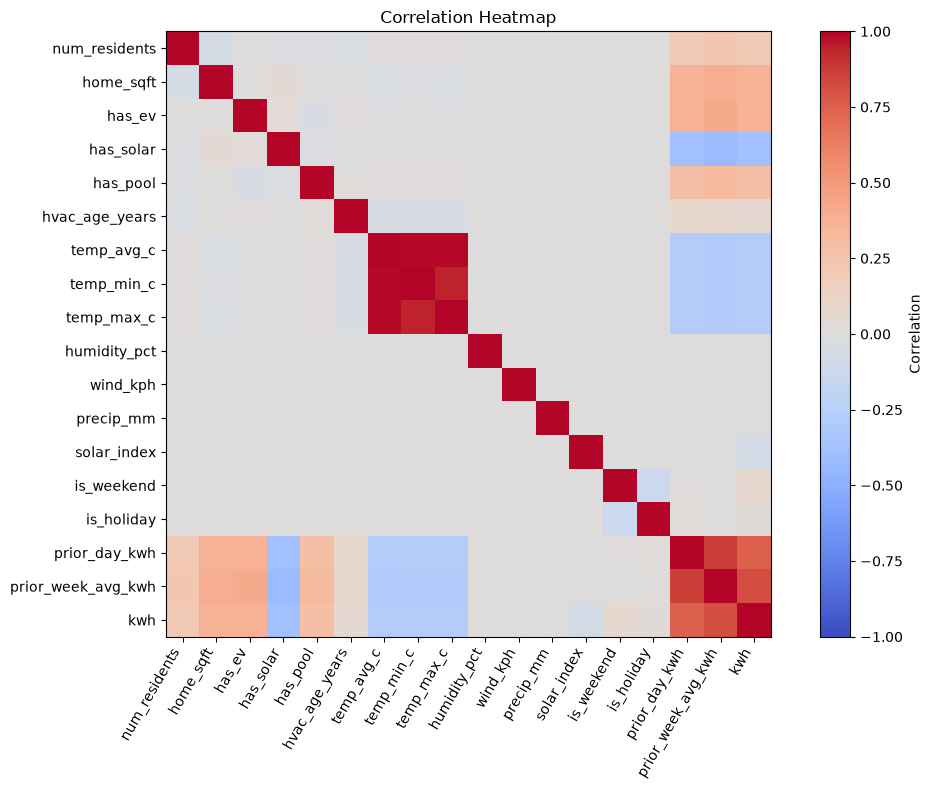

kwh                   1.000000
prior_week_avg_kwh    0.819591
prior_day_kwh         0.747664
has_ev                0.370560
home_sqft             0.361046
has_pool              0.285829
num_residents         0.204189
is_weekend            0.071569
hvac_age_years        0.070211
is_holiday            0.026851
humidity_pct          0.007651
wind_kph              0.000091
precip_mm            -0.001897
solar_index          -0.066059
temp_min_c           -0.275231
temp_max_c           -0.275961
temp_avg_c           -0.279810
has_solar            -0.382553
Name: kwh, dtype: float64

In [12]:
num_cols = df.select_dtypes(include="number").columns.drop("row_id")
corr = df[num_cols].corr()

plt.figure(figsize=(11, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=60, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(corr["kwh"].sort_values(ascending=False))

### 5.7 Outliers in the target (IQR method)

In [13]:
Q1 = df["kwh"].quantile(0.25)
Q3 = df["kwh"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df["kwh"] < lower) | (df["kwh"] > upper)]
print("Lower bound:", round(lower, 2), "| Upper bound:", round(upper, 2))
print("Outliers:", len(outliers), f"({len(outliers)/len(df)*100:.2f}%)")

Lower bound: 3.96 | Upper bound: 47.43
Outliers: 1838 (2.08%)


These high/low values may represent real consumption days (e.g. very cold days or large homes), so we **keep them** unless domain checks show they are data errors.

## 6. Data Preprocessing

In [14]:
df_prep = df.copy()

# Date features
df_prep["date"] = pd.to_datetime(df_prep["date"])
df_prep["day_of_week"] = df_prep["date"].dt.dayofweek

print(df_prep[["date", "day_of_week"]].head())

        date  day_of_week
0 2025-01-02            3
1 2025-01-03            4
2 2025-01-04            5
3 2025-01-05            6
4 2025-01-06            0


### 6.1 Train / Test Split

The test set is the **future** (last 14 days per household), so we split **by date** instead of randomly — this mimics the real task.

In [15]:
split_date = df_prep["date"].max() - pd.Timedelta(days=13)
print("Validation starts from:", split_date.date())

train_df = df_prep[df_prep["date"] < split_date]
test_df  = df_prep[df_prep["date"] >= split_date]

drop_cols = ["row_id", "household_id", "date", "kwh"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["kwh"]
X_test  = test_df.drop(columns=drop_cols)
y_test  = test_df["kwh"]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Validation starts from: 2025-02-16
X_train: (67500, 19) | X_test: (21000, 19)


### 6.2 Preprocessing pipeline (scaling + encoding)

In [16]:
cat_cols = ["heating_type"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns: ['num_residents', 'home_sqft', 'has_ev', 'has_solar', 'has_pool', 'hvac_age_years', 'temp_avg_c', 'temp_min_c', 'temp_max_c', 'humidity_pct', 'wind_kph', 'precip_mm', 'solar_index', 'is_weekend', 'is_holiday', 'prior_day_kwh', 'prior_week_avg_kwh', 'day_of_week']
Categorical columns: ['heating_type']


## 7. Model Training

In [17]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, n_jobs=-1, random_state=42
    ),
    "KNN Regressor": KNeighborsRegressor(
        n_neighbors=7, weights="distance", p=2, n_jobs=-1
    ),
    # RBF-SVR can be very slow on large datasets. Train it on a deterministic
    # subset for a practical baseline; evaluate it on the full validation set.
    "SVR (RBF)": SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale"),
}

pipelines = {}
svr_train_limit = 5000

for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])

    if name == "SVR (RBF)" and len(X_train) > svr_train_limit:
        # Keep runtime manageable for kernel SVR.
        rng = np.random.RandomState(42)
        sample_idx = rng.choice(len(X_train), size=svr_train_limit, replace=False)
        X_fit = X_train.iloc[sample_idx]
        y_fit = y_train.iloc[sample_idx]
        print(f"Training {name} on a reproducible sample of {len(X_fit):,} rows.")
    else:
        X_fit = X_train
        y_fit = y_train

    pipe.fit(X_fit, y_fit)
    pipelines[name] = pipe
    print(name, "trained")


Linear Regression trained
Random Forest trained
KNN Regressor trained
Training SVR (RBF) on a reproducible sample of 5,000 rows.
SVR (RBF) trained


## 8. Model Evaluation

In [18]:
results = []
predictions = {}

for name, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)


,Model,MAE,RMSE,R2
0,Linear Regression,3.233691,4.325767,0.749384
1,Random Forest,3.206699,4.375165,0.743627
2,SVR (RBF),3.260860,4.500006,0.728788
3,KNN Regressor,3.339558,4.546574,0.723146


## 9. Model Comparison

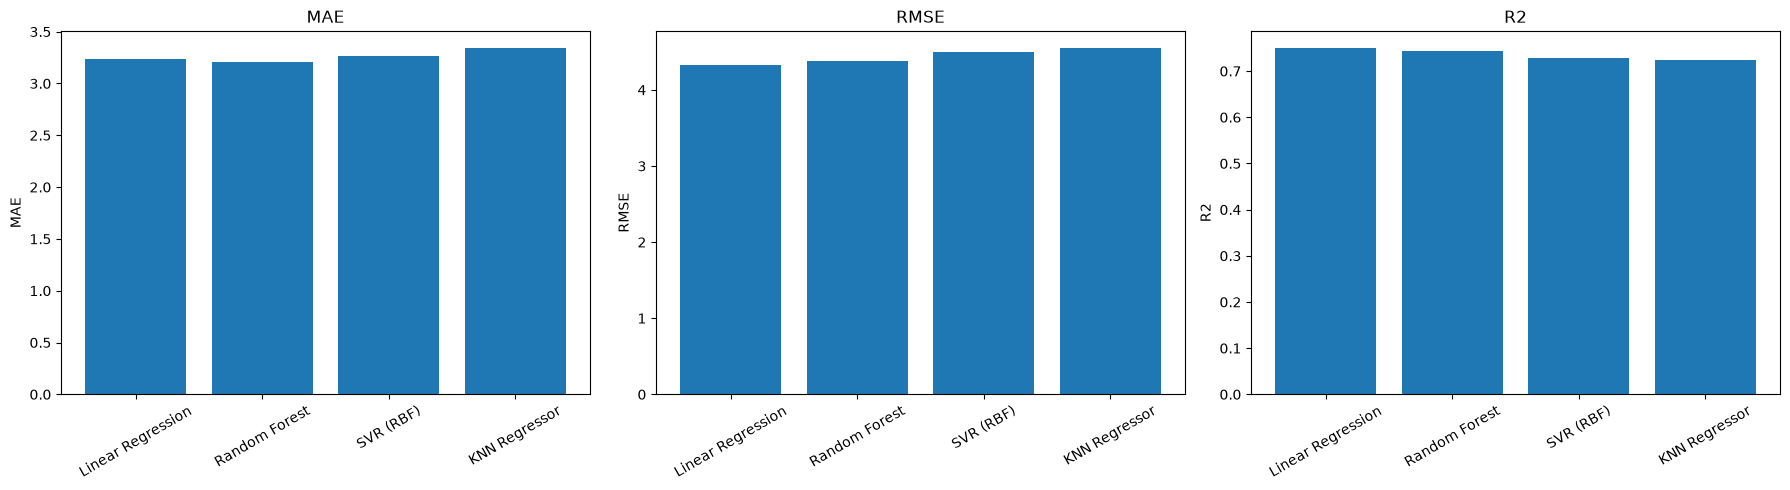

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel(metric)
plt.tight_layout()
plt.show()


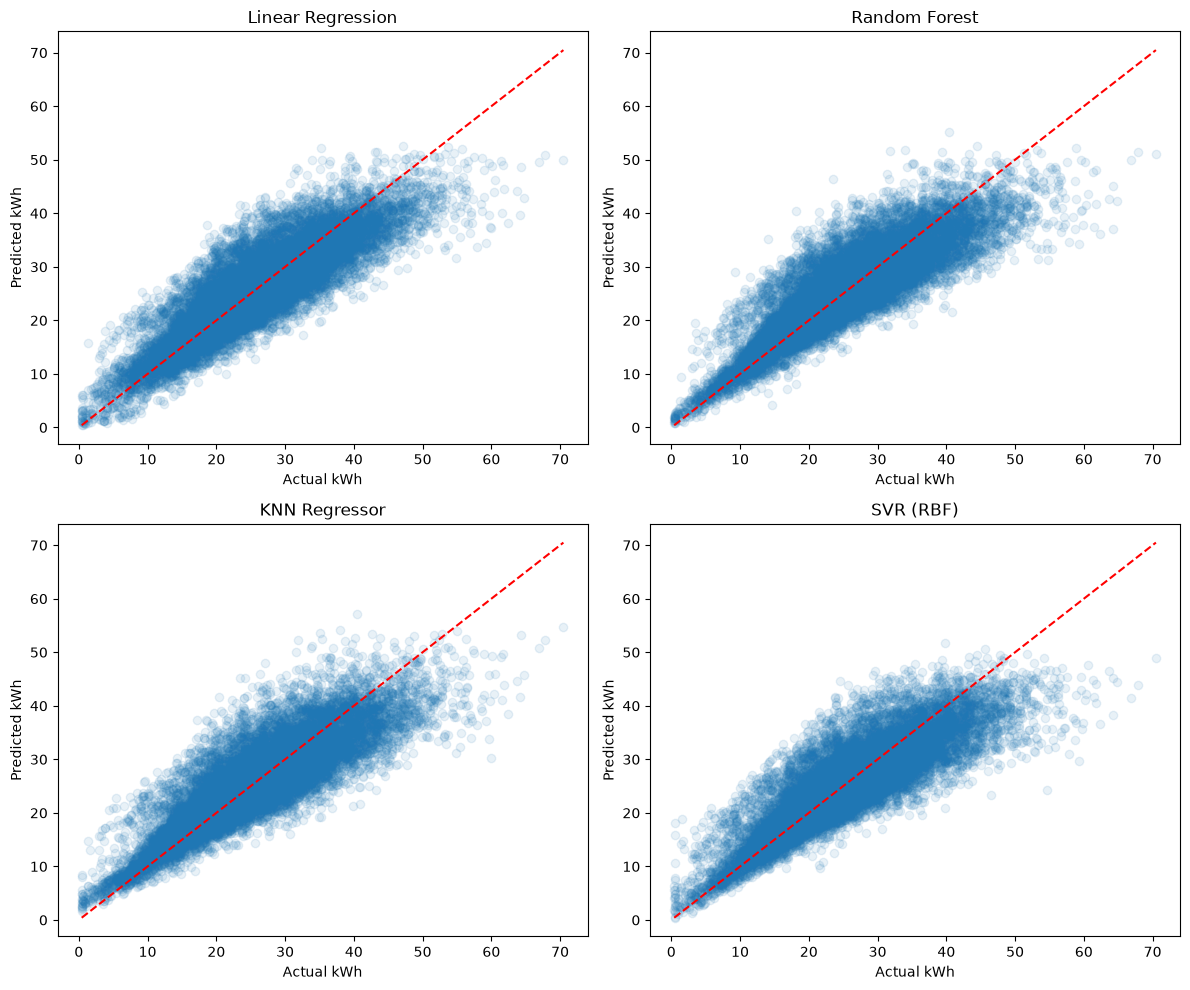

In [20]:
# Actual vs predicted for all models
n_models = len(predictions)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.1)
    min_val = min(float(y_test.min()), float(np.min(pred)))
    max_val = max(float(y_test.max()), float(np.max(pred)))
    ax.plot([min_val, max_val], [min_val, max_val], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual kWh")
    ax.set_ylabel("Predicted kWh")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 10. Best Model Selection

Select the model with the **lowest validation RMSE**. RMSE is used here as the primary comparison metric; MAE and R² are reported as supporting metrics.

**Important:** `SVR (RBF)` is trained on a reproducible subset when the training set exceeds 5,000 rows because kernel SVR can be computationally expensive. Its validation scores should therefore be interpreted as a practical baseline rather than a fully trained-on-all-rows result.

In [21]:
best_idx = results_df["RMSE"].idxmin()
best_name = results_df.loc[best_idx, "Model"]
best_pipeline = pipelines[best_name]

print("Best model:", best_name)
display(results_df.loc[[best_idx]])

Best model: Linear Regression


,Model,MAE,RMSE,R2
0,Linear Regression,3.233691,4.325767,0.749384


In [22]:
# Feature importance (only if the best model is Random Forest)
if best_name == "Random Forest":
    feature_names = best_pipeline.named_steps["preprocess"].get_feature_names_out()
    importances = pd.Series(best_pipeline.named_steps["model"].feature_importances_, index=feature_names)
    importances = importances.sort_values()
    plt.figure(figsize=(8, 6))
    plt.barh(importances.index, importances.values)
    plt.title("Feature Importance")
    plt.tight_layout()
    plt.show()

## 11. Save the Best Model and Preprocessing Pipeline

Save the **entire fitted pipeline** (preprocessing + model) in one file. The preprocessing step contains `StandardScaler` for numeric features and `OneHotEncoder` for categorical features, so they are saved together with the trained estimator.

The best pipeline is saved separately for deployment/submission. Individual fitted pipelines are also saved so the models can be reused later without retraining.

In [23]:
# Save the fitted preprocessing steps and model together in Pipeline files
from pathlib import Path
import pickle

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the best-performing fitted pipeline
best_pipeline_path = models_dir / "best_model_pipeline.pkl"
with open(best_pipeline_path, "wb") as f:
    pickle.dump(best_pipeline, f)
print(f"Saved best pipeline: {best_pipeline_path}")
print(f"Best model: {best_name}")

# Save each fitted model pipeline separately for future reuse
for model_name, fitted_pipeline in pipelines.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "_")
    )
    model_path = models_dir / f"{safe_name}_pipeline.pkl"
    with open(model_path, "wb") as f:
        pickle.dump(fitted_pipeline, f)
    print(f"Saved {model_name}: {model_path}")

Saved best pipeline: models\best_model_pipeline.pkl
Best model: Linear Regression
Saved Linear Regression: models\linear_regression_pipeline.pkl
Saved Random Forest: models\random_forest_pipeline.pkl
Saved KNN Regressor: models\knn_regressor_pipeline.pkl
Saved SVR (RBF): models\svr_rbf_pipeline.pkl


## 12. Test the saved pipeline on test.csv

In [24]:
# Load the saved best pipeline (preprocessing + model)
with open("models/best_model_pipeline.pkl", "rb") as f:
    loaded = pickle.load(f)

test = pd.read_csv("test.csv")
test["date"] = pd.to_datetime(test["date"])
test["day_of_week"] = test["date"].dt.dayofweek

X_new = test[X_train.columns]
test["kwh"] = loaded.predict(X_new)

submission = test[["row_id", "kwh"]]
submission.to_csv("submission.csv", index=False)
display(submission.head())

print("Saved submission.csv")

,row_id,kwh
0,59,25.670117
1,60,25.268798
2,61,24.913143
3,62,24.411878
4,63,24.662371


Saved submission.csv
